# Linear Regression from Scratch

This notebook implements linear regression two ways, using only NumPy:

1. **Closed-form solution** with the Moore–Penrose pseudo-inverse
2. **Gradient descent**, learning the coefficients iteratively

Both are then checked against scikit-learn's `LinearRegression`, and the notebook ends with a comparison of simple and multiple linear regression.

**Contents**
1. The math
2. Closed-form fit on a small dataset
3. How noise affects the fit
4. Gradient descent
5. Verification against scikit-learn
6. Simple vs multiple linear regression
7. Key takeaways

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

np.random.seed(42)  # makes every random result in this notebook reproducible

## 1. The math

Linear regression models the output $y$ as a weighted sum of the inputs:

$$\hat{y} = Xb$$

where $X$ is the input matrix (one row per sample, plus a column of ones for the intercept) and $b$ is the vector of coefficients.

We choose $b$ to minimise the **mean squared error** between predictions and actual values:

$$\text{MSE}(b) = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2$$

Setting the gradient of the MSE to zero gives the **normal equation**:

$$b = (X^TX)^{-1}X^Ty$$

The term $(X^TX)^{-1}X^T$ is the **pseudo-inverse** of $X$, written $X^+$. NumPy computes it with `np.linalg.pinv`, which also works when $X^TX$ cannot be inverted, so the solution is simply:

$$b = X^+y$$

## 2. Closed-form fit on a small dataset

A 5-point dataset is small enough to see exactly what the model is doing.

A column of ones is added to $X$ so the model can learn an **intercept**. Without it, the fitted line would be forced through the origin.

slope = 0.7872, intercept = 0.0822
R²  = 0.9776


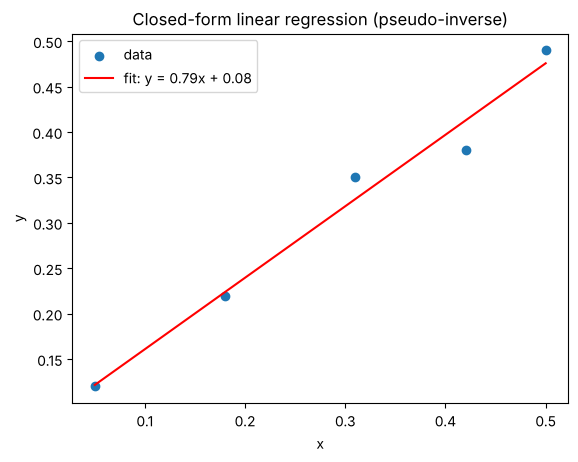

In [2]:
data = np.array([
    [0.05, 0.12],
    [0.18, 0.22],
    [0.31, 0.35],
    [0.42, 0.38],
    [0.50, 0.49],
])
x_small, y_small = data[:, 0], data[:, 1]

# design matrix: [x, 1] so the model learns slope and intercept
X_small = np.column_stack([x_small, np.ones_like(x_small)])

b_small = np.linalg.pinv(X_small) @ y_small
slope, intercept = b_small
print(f"slope = {slope:.4f}, intercept = {intercept:.4f}")

yhat_small = X_small @ b_small
print(f"R²  = {r2_score(y_small, yhat_small):.4f}")

plt.scatter(x_small, y_small, label="data")
plt.plot(x_small, yhat_small, color="red", label=f"fit: y = {slope:.2f}x + {intercept:.2f}")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Closed-form linear regression (pseudo-inverse)")
plt.legend()
plt.show()

The line passes close to all five points, and the R² near 1 confirms that a straight line explains almost all of the variation in this data.

## 3. How noise affects the fit

Next, data is generated from a **known** line, $y = 2x + 3$, with Gaussian noise added:

$$y_i = 2x_i + 3 + \sigma \cdot N(0, 1)$$

Because the true slope (2) and intercept (3) are known, we can see how well the model recovers them as the noise level $\sigma$ grows.

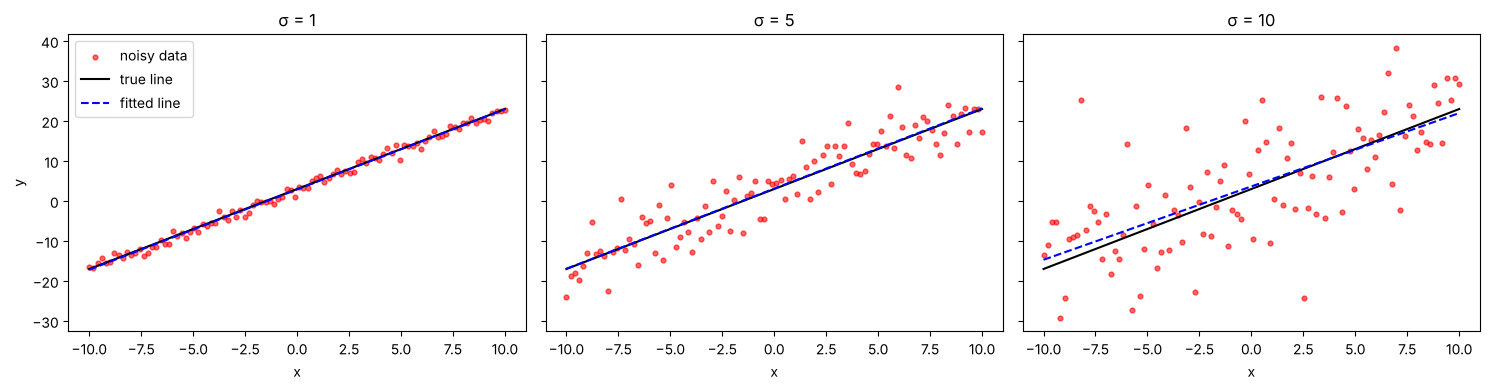

,sigma,fitted slope,fitted intercept,R²,MAE
0,1,2.007,2.896,0.994,0.715
1,5,2.005,3.112,0.859,3.771
2,10,1.834,3.649,0.498,8.452


In [3]:
n = 100
x = np.linspace(-10, 10, n)
TRUE_SLOPE, TRUE_INTERCEPT = 2, 3
X = np.column_stack([x, np.ones(n)])

def fit_pinv(X, y):
    # closed-form least squares
    return np.linalg.pinv(X) @ y

sigmas = [1, 5, 10]
datasets = {}
rows = []

fig, axes = plt.subplots(1, len(sigmas), figsize=(15, 4), sharey=True)
for ax, sigma in zip(axes, sigmas):
    y = TRUE_SLOPE * x + TRUE_INTERCEPT + sigma * np.random.normal(0, 1, n)
    datasets[sigma] = y
    b = fit_pinv(X, y)
    yhat = X @ b
    rows.append({
        "sigma": sigma,
        "fitted slope": round(b[0], 3),
        "fitted intercept": round(b[1], 3),
        "R²": round(r2_score(y, yhat), 3),
        "MAE": round(mean_absolute_error(y, yhat), 3),
    })
    ax.scatter(x, y, color="red", s=12, alpha=0.6, label="noisy data")
    ax.plot(x, TRUE_SLOPE * x + TRUE_INTERCEPT, color="black", label="true line")
    ax.plot(x, yhat, color="blue", linestyle="--", label="fitted line")
    ax.set_title(f"σ = {sigma}")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].legend()
plt.tight_layout()
plt.show()

pd.DataFrame(rows)

**What this shows:**
- At low and moderate noise ($\sigma$ = 1 and 5), the fitted slope and intercept are very close to the true values of 2 and 3.
- At high noise ($\sigma$ = 10), both estimates drift noticeably. More noise means less certainty about the coefficients.
- **R² falls and MAE rises as noise grows.** The model is not getting worse at finding the line; there is simply more variation in $y$ that no straight line can explain. R² measures how much of the variation is explained, not whether the model found the true relationship.

## 4. Gradient descent

The pseudo-inverse solves for $b$ in one step. Gradient descent instead **starts from a guess and repeatedly moves the coefficients downhill** on the MSE. This is how most machine learning models are trained, including models that have no closed-form solution.

The gradients of the MSE with respect to the slope $w$ and intercept $c$ are:

$$\frac{\partial\,\text{MSE}}{\partial w} = \frac{2}{n}\sum(\hat{y}_i - y_i)\,x_i \qquad \frac{\partial\,\text{MSE}}{\partial c} = \frac{2}{n}\sum(\hat{y}_i - y_i)$$

Each step updates both parameters by a small amount (the **learning rate**) in the opposite direction of the gradient.

Gradient descent: slope = 2.0050, intercept = 3.1115
Pseudo-inverse:   slope = 2.0050, intercept = 3.1115


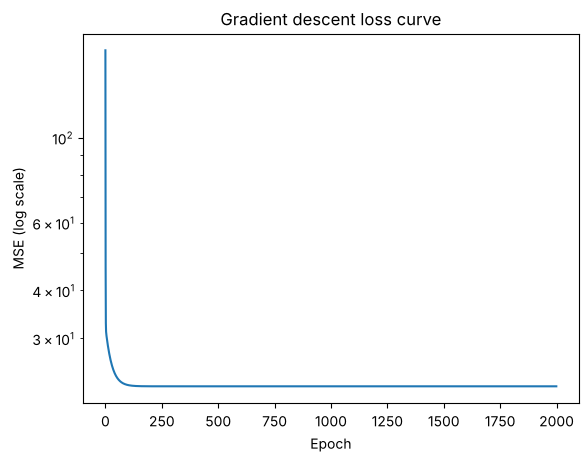

In [4]:
def gradient_descent(x, y, learning_rate=0.01, n_epochs=2000):
    w, c = 0.0, 0.0           # start from zero
    n = len(x)
    losses = []
    for _ in range(n_epochs):
        y_pred = w * x + c
        error = y_pred - y
        losses.append(np.mean(error ** 2))
        dw = (2 / n) * np.sum(error * x)
        dc = (2 / n) * np.sum(error)
        w -= learning_rate * dw
        c -= learning_rate * dc
    return w, c, losses

y5 = datasets[5]  # reuse the σ = 5 data from section 3
w_gd, c_gd, losses = gradient_descent(x, y5)
w_pinv, c_pinv = fit_pinv(X, y5)

print(f"Gradient descent: slope = {w_gd:.4f}, intercept = {c_gd:.4f}")
print(f"Pseudo-inverse:   slope = {w_pinv:.4f}, intercept = {c_pinv:.4f}")

plt.plot(losses)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE (log scale)")
plt.title("Gradient descent loss curve")
plt.show()

Gradient descent converges to the same coefficients as the closed-form solution.

The loss curve drops steeply at first, as the slope is learned within a few dozen epochs, then levels off once the intercept settles. Its final value is the irreducible error caused by the noise.

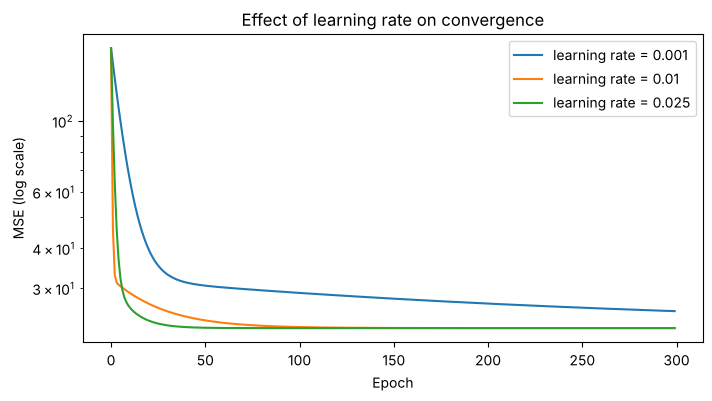

learning rate = 0.05 → MSE after 20 epochs: 3.88e+16 (diverging)


In [5]:
# effect of the learning rate
plt.figure(figsize=(8, 4))
for lr in [0.001, 0.01, 0.025]:
    _, _, l = gradient_descent(x, y5, learning_rate=lr, n_epochs=300)
    plt.plot(l, label=f"learning rate = {lr}")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE (log scale)")
plt.title("Effect of learning rate on convergence")
plt.legend()
plt.show()

# a learning rate that is too large makes the loss explode
_, _, l_big = gradient_descent(x, y5, learning_rate=0.05, n_epochs=20)
print(f"learning rate = 0.05 → MSE after 20 epochs: {l_big[-1]:.2e} (diverging)")

- A **small** learning rate converges, but slowly.
- A **larger** one converges faster.
- A learning rate that is **too large** overshoots the minimum on every step and the loss grows without limit. Choosing the learning rate is a trade-off between speed and stability.

## 5. Verification against scikit-learn

scikit-learn's `LinearRegression` solves the same least-squares problem, so all three methods should give the same coefficients.

In [6]:
sk_model = LinearRegression().fit(x.reshape(-1, 1), y5)

comparison = pd.DataFrame({
    "slope": [w_pinv, w_gd, sk_model.coef_[0]],
    "intercept": [c_pinv, c_gd, sk_model.intercept_],
}, index=["Pseudo-inverse (NumPy)", "Gradient descent (NumPy)", "scikit-learn"])
print(comparison.round(4))

assert np.allclose([w_pinv, c_pinv], [sk_model.coef_[0], sk_model.intercept_])
assert np.allclose([w_gd, c_gd], [sk_model.coef_[0], sk_model.intercept_], atol=1e-3)
print("\nAll three methods agree.")

                          slope  intercept
Pseudo-inverse (NumPy)    2.005     3.1115
Gradient descent (NumPy)  2.005     3.1115
scikit-learn              2.005     3.1115

All three methods agree.


## 6. Simple vs multiple linear regression

So far the model has used one input. **Multiple linear regression** uses several inputs at once.

This example uses a synthetic dataset of 50 films, where a film's rating depends on both its budget and its box-office earnings. Box office is itself driven by budget, so the two inputs are correlated.

In [7]:
np.random.seed(1)
budget = np.random.randint(50, 200, 50)
box_office = budget * np.random.uniform(1.5, 2.5, 50)
rating = 0.03 * budget + 0.01 * box_office + np.random.normal(0, 1, 50)

df = pd.DataFrame({"Budget": budget, "BoxOffice": box_office, "Rating": rating})
print(f"Correlation between Budget and BoxOffice: {df['Budget'].corr(df['BoxOffice']):.2f}")
df.head()

Correlation between Budget and BoxOffice: 0.93


,Budget,BoxOffice,Rating
0,87,184.790609,4.274369
1,190,410.520789,9.252233
2,122,219.416426,5.698451
3,187,363.927153,9.821664
4,183,315.148792,9.401443


In [8]:
y_r = df["Rating"]
results = {}

for name, features in {"Simple (Budget)": ["Budget"],
                       "Multiple (Budget + BoxOffice)": ["Budget", "BoxOffice"]}.items():
    X_train, X_test, y_train, y_test = train_test_split(
        df[features], y_r, test_size=0.2, random_state=1)
    model = LinearRegression().fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[name] = {"model": model, "X_test": X_test, "y_test": y_test, "y_pred": y_pred}
    print(f"{name}")
    print(f"  coefficients: { {f: round(float(c), 4) for f, c in zip(features, model.coef_)} }")
    print(f"  test R²: {r2_score(y_test, y_pred):.3f}   test MAE: {mean_absolute_error(y_test, y_pred):.3f}\n")

Simple (Budget)
  coefficients: {'Budget': 0.0462}
  test R²: 0.903   test MAE: 0.631

Multiple (Budget + BoxOffice)
  coefficients: {'Budget': 0.0309, 'BoxOffice': 0.0078}
  test R²: 0.912   test MAE: 0.668



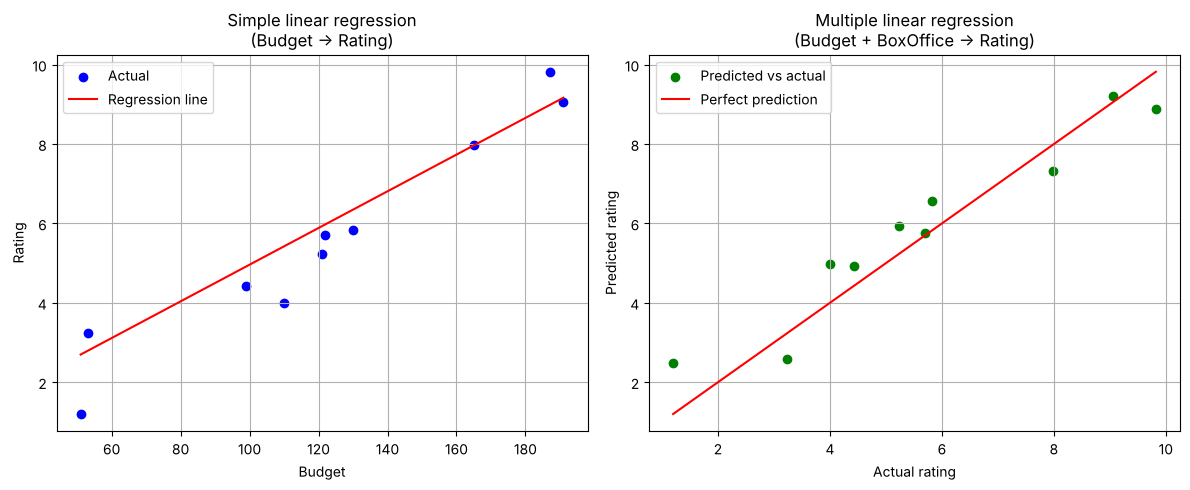

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

s = results["Simple (Budget)"]
ax1.scatter(s["X_test"], s["y_test"], color="blue", label="Actual")
x_line = np.linspace(s["X_test"].min().iloc[0], s["X_test"].max().iloc[0], 100)
ax1.plot(x_line, s["model"].predict(pd.DataFrame({"Budget": x_line})),
         color="red", label="Regression line")
ax1.set_xlabel("Budget")
ax1.set_ylabel("Rating")
ax1.set_title("Simple linear regression\n(Budget → Rating)")
ax1.legend()
ax1.grid(True)

m = results["Multiple (Budget + BoxOffice)"]
lims = [m["y_test"].min(), m["y_test"].max()]
ax2.scatter(m["y_test"], m["y_pred"], color="green", label="Predicted vs actual")
ax2.plot(lims, lims, color="red", label="Perfect prediction")
ax2.set_xlabel("Actual rating")
ax2.set_ylabel("Predicted rating")
ax2.set_title("Multiple linear regression\n(Budget + BoxOffice → Rating)")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

**Interpreting the results:**
- The two models score almost the same: the multiple model has a slightly higher R² but a slightly higher MAE. The test set has only 10 films, so differences this small are not meaningful.
- The coefficients are more revealing. The data was generated as $0.03 \times \text{Budget} + 0.01 \times \text{BoxOffice}$. The multiple model recovers values close to these. The simple model's Budget coefficient is larger, because Budget is also standing in for the box-office effect it cannot see.
- Because Budget and BoxOffice are strongly correlated, they carry overlapping information. This is called **multicollinearity**. It makes the individual coefficients in the multiple model less stable and harder to interpret, even when its predictions are good.
- With one input, the model is a line you can plot directly. With two or more, a **predicted vs actual** plot is the usual way to visualise fit: the closer the points are to the diagonal, the better.

## 7. Key takeaways

- Linear regression finds the coefficients that minimise mean squared error. The pseudo-inverse solves this directly in one step.
- Gradient descent reaches the same answer iteratively. Its behaviour depends heavily on the learning rate: too small is slow, too large diverges.
- Both from-scratch implementations match scikit-learn's `LinearRegression`.
- R² measures how much of the variation in $y$ the model explains. Noise lowers R² even when the model has found the true relationship.
- Adding a feature does not always improve predictions noticeably, but it can change what the coefficients mean. Correlated features make individual coefficients harder to interpret.

**Possible extensions:** regularisation (Ridge and Lasso), applying the model to a real dataset, and splitting data into training and test sets before evaluating the from-scratch models.